# Watch a vanishing starting error grow
Run with OneSimulation, NumPy and Matplotlib installed.
Vary the number of steps and the injected starting error. Compare both perturbation amplification and the error of the reference trajectory.

Root -1: change at T=1 with 26 steps: 6.6793e-05
Root +2: change at T=1 with 26 steps: 8875.58
Reference RK4 error with 26 steps: 6.93e-09


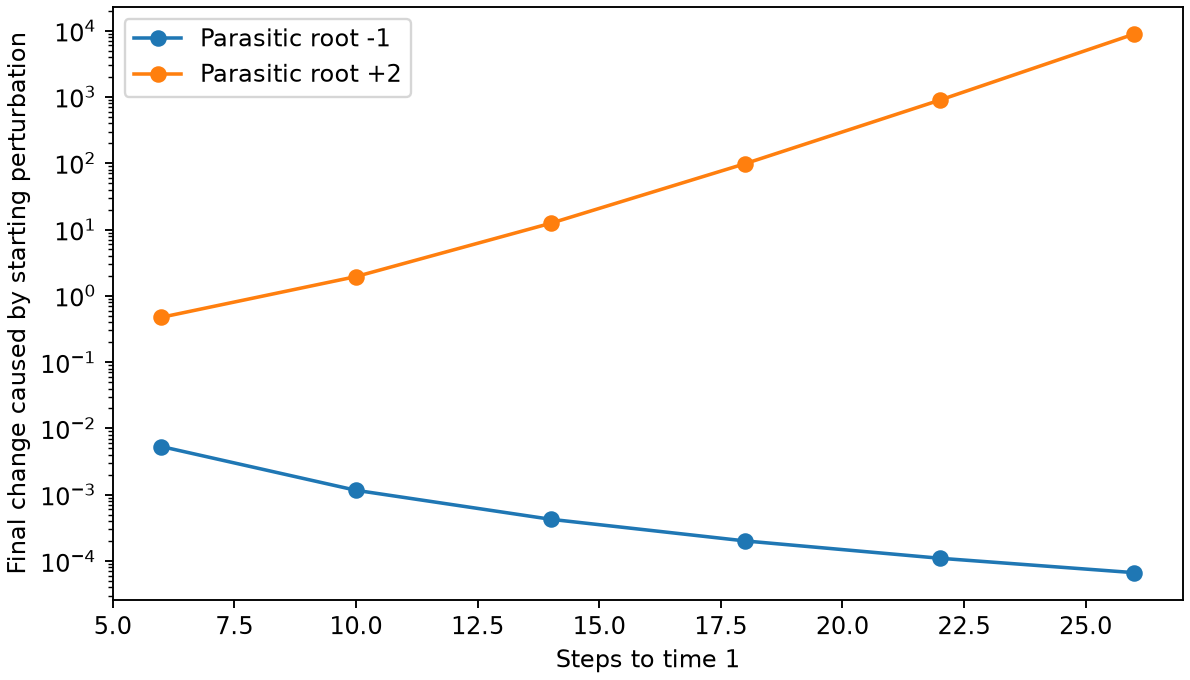

In [1]:
"""Resolve a decaying signal with two consistent families of two-step methods."""
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.time import ClassicalRungeKutta4TimeIntegrator

def decay(state, time):
    return (-state[0],)

def endpoint(parasitic, starter, h, n):
    previous, current = 1.0, starter
    for _ in range(1, n):
        previous, current = current, (1+parasitic-h*(1-parasitic))*current-parasitic*previous
    return current

method = ClassicalRungeKutta4TimeIntegrator()
counts = [6, 10, 14, 18, 22, 26]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for parasitic in [-1, 2]:
    errors = []
    for n in counts:
        h = 1/n
        reference = (1.0,)
        starter = method.advance(reference, decay, h, time=0.)[0]
        for j in range(n):
            reference = method.advance(reference, decay, h, time=j*h)
        unperturbed = endpoint(parasitic, starter, h, n)
        perturbed = endpoint(parasitic, starter+h**3, h, n)
        errors.append(abs(perturbed-unperturbed))
        assert abs(reference[0] - np.exp(-1)) < 1e-5
    ax.semilogy(counts, errors, "o-", label=f"Parasitic root {parasitic:+d}")
    print(f"Root {parasitic:+d}: change at T=1 with 26 steps: {errors[-1]:.6g}")
print(f"Reference RK4 error with 26 steps: {abs(reference[0]-np.exp(-1)):.3g}")
ax.set(xlabel="Steps to time 1", ylabel="Final change caused by starting perturbation")
ax.legend()
fig.savefig("numerics-parasitic-root.png", dpi=170)
